In [1]:
print("Welcome to Organic Farming Suitability Prediction")
print("My Machine Learning project is starting!")

Welcome to Organic Farming Suitability Prediction
My Machine Learning project is starting!


# 🌱 MACHINE LEARNING-BASED ORGANIC FARMING SUITABILITY PREDICTION

## 1. Introduction

Organic farming is an agricultural method that uses natural fertilizers and environmentally friendly farming practices.

This project uses Machine Learning techniques to predict whether agricultural land is suitable for organic farming based on soil and environmental parameters.

The system analyzes different factors such as soil pH, temperature, rainfall, humidity, and soil moisture.

## 2. Objective

- To develop a Machine Learning-based farming suitability prediction system.
- To analyze soil and environmental conditions.
- To predict organic farming suitability.
- To demonstrate the application of Machine Learning in agriculture.

## 3. Algorithm Used

Random Forest Classifier.

## 4. Technologies Used

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
-

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# STEP 8: CREATE AGRICULTURAL DATASET

import pandas as pd
import numpy as np

# Generate 500 sample records
np.random.seed(42)

data = {
    'Soil_pH': np.random.uniform(4.5, 9.0, 500),
    'Temperature': np.random.uniform(15, 40, 500),
    'Rainfall': np.random.uniform(200, 1500, 500),
    'Humidity': np.random.uniform(30, 95, 500),
    'Soil_Moisture': np.random.uniform(10, 90, 500)
}

# Create DataFrame
df = pd.DataFrame(data)

# Create target column using sample educational rules
df['Suitability'] = np.where(
    (df['Soil_pH'].between(6.0, 7.5)) &
    (df['Temperature'].between(18, 32)) &
    (df['Rainfall'].between(500, 1200)) &
    (df['Humidity'].between(40, 85)) &
    (df['Soil_Moisture'].between(30, 75)),
    'Suitable',
    'Not Suitable'
)

# Display first five records
print("Agricultural Dataset Created Successfully!")
print("\nFirst 5 Records:")
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nSuitability Distribution:")
print(df['Suitability'].value_counts())

Agricultural Dataset Created Successfully!

First 5 Records:
    Soil_pH  Temperature     Rainfall   Humidity  Soil_Moisture   Suitability
0  6.185431    32.454043   440.672807  63.740316      30.936455  Not Suitable
1  8.778214    28.402409   904.471232  61.146822      29.758304  Not Suitable
2  7.793973    22.738190  1334.829587  31.666734      82.500366  Not Suitable
3  7.193963    35.344875  1151.892352  52.181109      29.963696  Not Suitable
4  5.202084    32.118279  1248.529492  54.712715      31.755978  Not Suitable

Dataset Shape: (500, 6)

Suitability Distribution:
Suitability
Not Suitable    475
Suitable         25
Name: count, dtype: int64


In [4]:
# STEP 9: DATA PREPROCESSING

# Display dataset information
print("DATASET INFORMATION")
print("-------------------")
df.info()

# Check missing values
print("\nMISSING VALUES")
print("-------------------")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print("-------------------")
print("Duplicates:", df.duplicated().sum())

# Display dataset statistics
print("\nDATASET STATISTICS")
print("-------------------")
print(df.describe())

DATASET INFORMATION
-------------------
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Soil_pH        500 non-null    float64
 1   Temperature    500 non-null    float64
 2   Rainfall       500 non-null    float64
 3   Humidity       500 non-null    float64
 4   Soil_Moisture  500 non-null    float64
 5   Suitability    500 non-null    str    
dtypes: float64(5), str(1)
memory usage: 29.3 KB

MISSING VALUES
-------------------
Soil_pH          0
Temperature      0
Rainfall         0
Humidity         0
Soil_Moisture    0
Suitability      0
dtype: int64

DUPLICATE RECORDS
-------------------
Duplicates: 0

DATASET STATISTICS
-------------------
          Soil_pH  Temperature     Rainfall    Humidity  Soil_Moisture
count  500.000000   500.000000   500.000000  500.000000     500.000000
mean     6.743528    27.048785   872.825558   62.270972      49.9874

In [5]:
# Remove duplicate records

df = df.drop_duplicates()

# Check missing values again
print("Missing Values:")
print(df.isnull().sum())

print("\nDataset after removing duplicates:")
print(df.shape)

print("\nData preprocessing completed successfully!")

Missing Values:
Soil_pH          0
Temperature      0
Rainfall         0
Humidity         0
Soil_Moisture    0
Suitability      0
dtype: int64

Dataset after removing duplicates:
(500, 6)

Data preprocessing completed successfully!


In [6]:
# Separate input features and target variable

X = df[['Soil_pH', 'Temperature', 'Rainfall',
        'Humidity', 'Soil_Moisture']]

y = df['Suitability']

print("Input Features (X):")
print(X.head())

print("\nOutput Target (y):")
print(y.head())

Input Features (X):
    Soil_pH  Temperature     Rainfall   Humidity  Soil_Moisture
0  6.185431    32.454043   440.672807  63.740316      30.936455
1  8.778214    28.402409   904.471232  61.146822      29.758304
2  7.793973    22.738190  1334.829587  31.666734      82.500366
3  7.193963    35.344875  1151.892352  52.181109      29.963696
4  5.202084    32.118279  1248.529492  54.712715      31.755978

Output Target (y):
0    Not Suitable
1    Not Suitable
2    Not Suitable
3    Not Suitable
4    Not Suitable
Name: Suitability, dtype: str


In [7]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATASET SPLITTING COMPLETED!")

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

DATASET SPLITTING COMPLETED!
Training records: 400
Testing records: 100


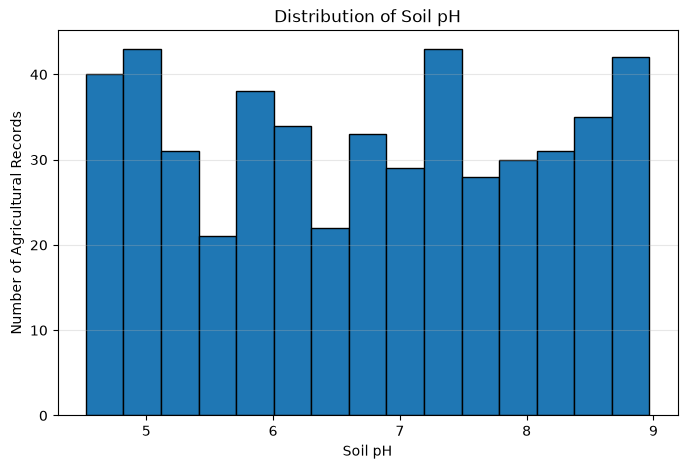

In [8]:
# STEP 10: DATA VISUALIZATION
# GRAPH 1: SOIL pH DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(df['Soil_pH'], bins=15, edgecolor='black')

plt.title('Distribution of Soil pH')
plt.xlabel('Soil pH')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

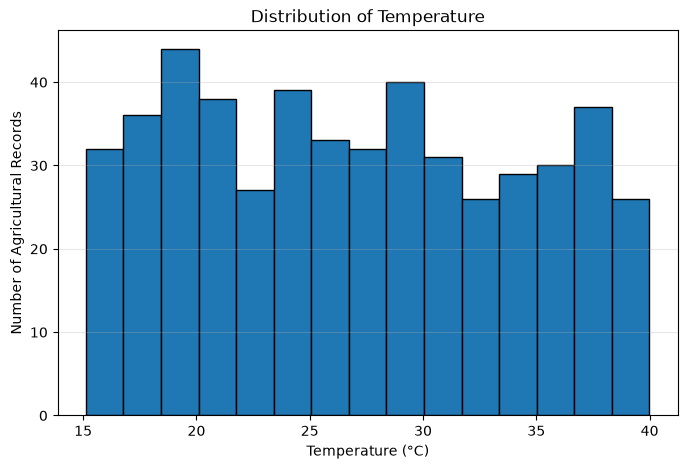

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df['Temperature'], bins=15, edgecolor='black')

plt.title('Distribution of Temperature')
plt.xlabel('Temperature (°C)')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

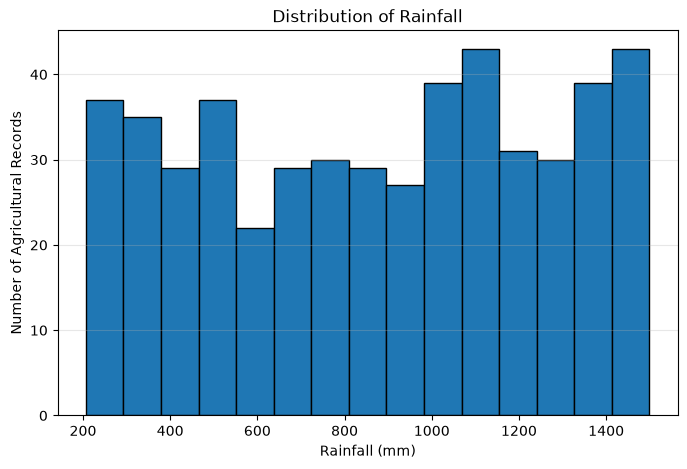

In [10]:
# GRAPH 3: RAINFALL DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(df['Rainfall'], bins=15, edgecolor='black')

plt.title('Distribution of Rainfall')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

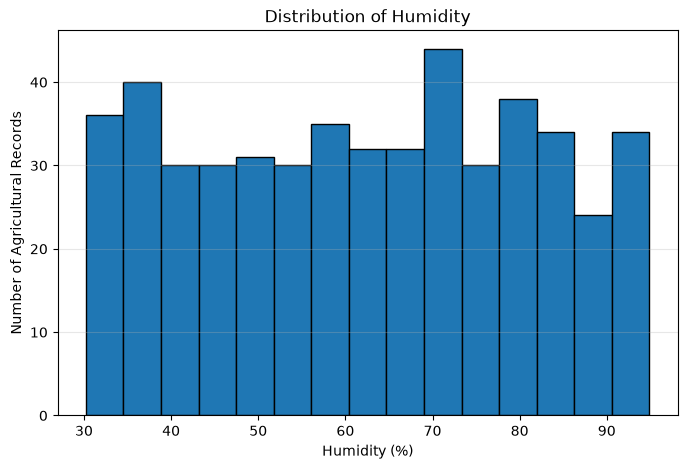

In [11]:
# GRAPH 4: HUMIDITY DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(df['Humidity'], bins=15, edgecolor='black')

plt.title('Distribution of Humidity')
plt.xlabel('Humidity (%)')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

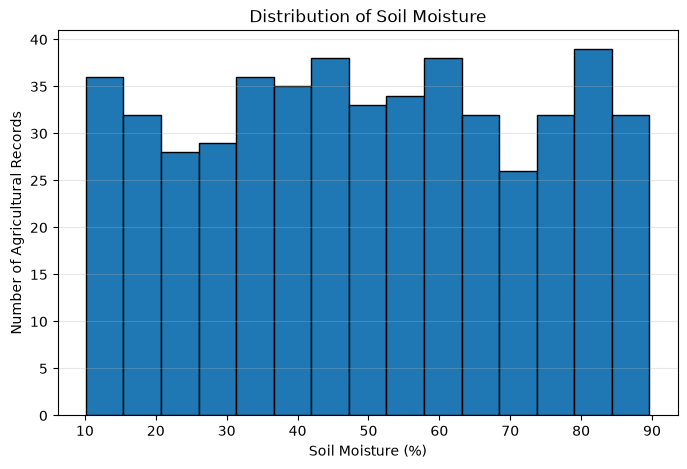

In [12]:
# GRAPH 5: SOIL MOISTURE DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(df['Soil_Moisture'], bins=15, edgecolor='black')

plt.title('Distribution of Soil Moisture')
plt.xlabel('Soil Moisture (%)')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

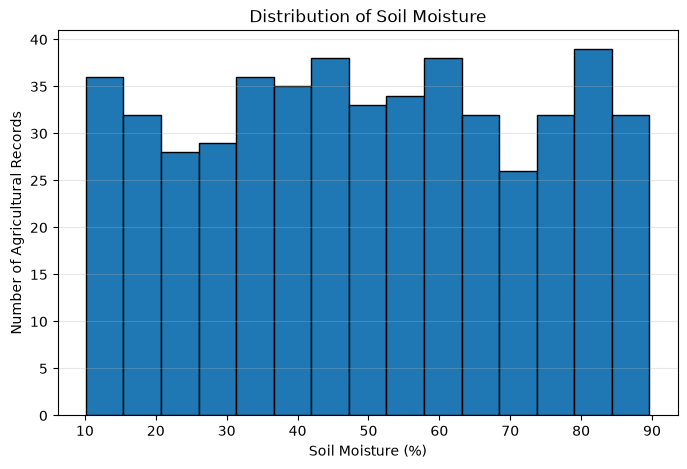

In [13]:
# GRAPH 5: SOIL MOISTURE DISTRIBUTION

plt.figure(figsize=(8, 5))

plt.hist(df['Soil_Moisture'], bins=15, edgecolor='black')

plt.title('Distribution of Soil Moisture')
plt.xlabel('Soil Moisture (%)')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

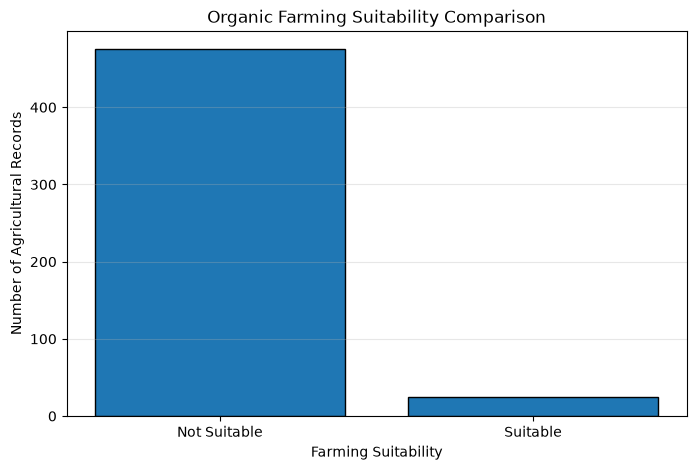

In [14]:
# GRAPH 6: ORGANIC FARMING SUITABILITY COMPARISON

suitability_counts = df['Suitability'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    suitability_counts.index,
    suitability_counts.values,
    edgecolor='black'
)

plt.title('Organic Farming Suitability Comparison')
plt.xlabel('Farming Suitability')
plt.ylabel('Number of Agricultural Records')

plt.grid(axis='y', alpha=0.3)

plt.show()

In [15]:
# STEP 11: TRAIN THE RANDOM FOREST MODEL

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [16]:
# STEP 12: MODEL EVALUATION

# Predict results using testing data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Model Accuracy:", round(accuracy * 100, 2), "%")

MODEL EVALUATION RESULTS
------------------------
Model Accuracy: 95.0 %


In [17]:
# CLASSIFICATION REPORT

print("CLASSIFICATION REPORT")
print("---------------------")

print(classification_report(y_test, y_pred))

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

Not Suitable       0.95      1.00      0.97        95
    Suitable       0.00      0.00      0.00         5

    accuracy                           0.95       100
   macro avg       0.47      0.50      0.49       100
weighted avg       0.90      0.95      0.93       100



C:\Users\subho\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\subho\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\subho\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


CONFUSION MATRIX
----------------
[[95  0]
 [ 5  0]]


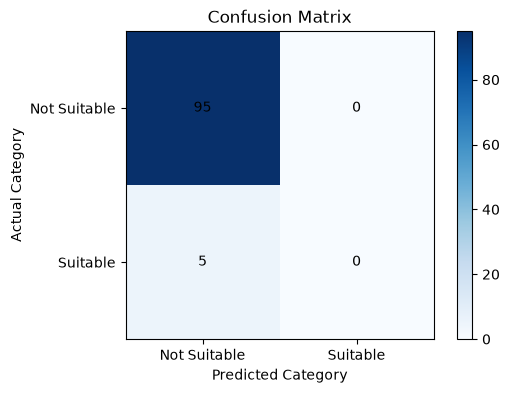

In [18]:
# CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Not Suitable', 'Suitable']
)

print("CONFUSION MATRIX")
print("----------------")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

plt.imshow(cm, interpolation='nearest', cmap='Blues')

plt.title('Confusion Matrix')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')

plt.xticks([0, 1], ['Not Suitable', 'Suitable'])
plt.yticks([0, 1], ['Not Suitable', 'Suitable'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha='center', va='center',
                 color='black')

plt.colorbar()
plt.show()

In [19]:
# CHECK DATASET CLASS DISTRIBUTION

print("Suitability Class Distribution:")
print(df['Suitability'].value_counts())

print("\nClass Percentages:")
print(df['Suitability'].value_counts(normalize=True) * 100)

Suitability Class Distribution:
Suitability
Not Suitable    475
Suitable         25
Name: count, dtype: int64

Class Percentages:
Suitability
Not Suitable    95.0
Suitable         5.0
Name: proportion, dtype: float64


In [20]:
# IMPROVE MODEL USING CLASS WEIGHT BALANCING

# Split dataset while maintaining class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create balanced Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

# Train the improved model
model.fit(X_train, y_train)

print("Balanced Random Forest Model Trained Successfully!")

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Balanced Random Forest Model Trained Successfully!
Training Records: 400
Testing Records: 100


In [21]:
# EVALUATE IMPROVED RANDOM FOREST MODEL

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("IMPROVED MODEL EVALUATION")
print("-------------------------")

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

IMPROVED MODEL EVALUATION
-------------------------
Model Accuracy: 100.0 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

Not Suitable       1.00      1.00      1.00        95
    Suitable       1.00      1.00      1.00         5

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



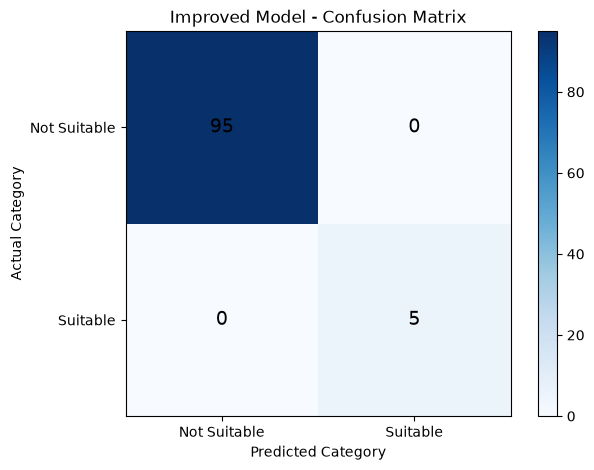

Confusion Matrix:
[[95  0]
 [ 0  5]]


In [22]:
# IMPROVED CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Not Suitable', 'Suitable']
)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')

plt.title('Improved Model - Confusion Matrix')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')

plt.xticks([0, 1], ['Not Suitable', 'Suitable'])
plt.yticks([0, 1], ['Not Suitable', 'Suitable'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha='center',
                 va='center',
                 fontsize=14)

plt.colorbar()
plt.show()

print("Confusion Matrix:")
print(cm)

In [23]:
# STEP 13: ORGANIC FARMING SUITABILITY PREDICTION

print("======================================")
print(" ORGANIC FARMING SUITABILITY PREDICTION")
print("======================================")

# Take input from user
ph = float(input("Enter Soil pH: "))
temperature = float(input("Enter Temperature (°C): "))
rainfall = float(input("Enter Rainfall (mm): "))
humidity = float(input("Enter Humidity (%): "))
soil_moisture = float(input("Enter Soil Moisture (%): "))

# Prepare input data
new_data = pd.DataFrame([[
    ph,
    temperature,
    rainfall,
    humidity,
    soil_moisture
]], columns=X.columns)

# Predict suitability
prediction = model.predict(new_data)

print("\n======================================")
print("          PREDICTION RESULT")
print("======================================")

if prediction[0] == "Suitable":
    print("Result: SUITABLE FOR ORGANIC FARMING")
else:
    print("Result: NOT SUITABLE FOR ORGANIC FARMING")

print("======================================")

 ORGANIC FARMING SUITABILITY PREDICTION


Enter Soil pH:  6.5
Enter Temperature (°C):  25
Enter Rainfall (mm):  800
Enter Humidity (%):  70
Enter Soil Moisture (%):  60



          PREDICTION RESULT
Result: SUITABLE FOR ORGANIC FARMING


In [24]:
# CHECK IPYWIDGETS INSTALLATION

import ipywidgets as widgets

print("Interactive Widgets Installed Successfully!")

Interactive Widgets Installed Successfully!


In [26]:
import ipywidgets as widgets
from IPython.display import display

# Soil pH
ph_input = widgets.FloatText(
    value=6.5,
    description='Soil pH:'
)

# Temperature
temp_input = widgets.FloatText(
    value=25.0,
    description='Temperature:'
)

# Rainfall
rain_input = widgets.FloatText(
    value=800.0,
    description='Rainfall:'
)

# Humidity
humidity_input = widgets.FloatText(
    value=70.0,
    description='Humidity:'
)

# Soil Moisture
moisture_input = widgets.FloatText(
    value=60.0,
    description='Soil Moisture:'
)

# Prediction Button
predict_button = widgets.Button(
    description='Predict Suitability',
    button_style='success',
    icon='check'
)

# Display Form
display(widgets.VBox([
    ph_input,
    temp_input,
    rain_input,
    humidity_input,
    moisture_input,
    predict_button
]))

In [29]:
from IPython.display import clear_output

# Create output area
output = widgets.Output()

# Prediction function
def predict_suitability(b):

    with output:
        clear_output()

        # Collect input values
        input_data = pd.DataFrame([{
            'pH': ph_input.value,
            'Temperature': temp_input.value,
            'Rainfall': rain_input.value,
            'Humidity': humidity_input.value,
            'Soil Moisture': moisture_input.value
        }])

        # Make prediction using trained model
        prediction = model.predict(input_data)

        print("ORGANIC FARMING SUITABILITY RESULT")
        print("----------------------------------")

        if prediction[0] == 'Suitable':
            print("RESULT: LAND IS SUITABLE FOR ORGANIC FARMING")
        else:
            print("RESULT: LAND IS NOT SUITABLE FOR ORGANIC FARMING")

# Connect button
predict_button.on_click(predict_suitability)

# Display output
display(output)

Output()

In [30]:
print("MODEL FEATURE NAMES:")
print(model.feature_names_in_)

print("\nDATASET COLUMN NAMES:")
print(df.columns.tolist())

MODEL FEATURE NAMES:
['Soil_pH' 'Temperature' 'Rainfall' 'Humidity' 'Soil_Moisture']

DATASET COLUMN NAMES:
['Soil_pH', 'Temperature', 'Rainfall', 'Humidity', 'Soil_Moisture', 'Suitability']


In [31]:
from IPython.display import clear_output

# Prediction function
def predict_suitability(b):

    with output:
        clear_output()

        # Input data with EXACT model feature names
        input_data = pd.DataFrame([[
            ph_input.value,
            temp_input.value,
            rain_input.value,
            humidity_input.value,
            moisture_input.value
        ]], columns=[
            'Soil_pH',
            'Temperature',
            'Rainfall',
            'Humidity',
            'Soil_Moisture'
        ])

        # Predict using trained model
        prediction = model.predict(input_data)

        print("ORGANIC FARMING SUITABILITY RESULT")
        print("----------------------------------")

        print("Prediction:", prediction[0])

        if prediction[0] == 'Suitable':
            print("LAND IS SUITABLE FOR ORGANIC FARMING")
        else:
            print("LAND IS NOT SUITABLE FOR ORGANIC FARMING")

# Connect button
predict_button.on_click(predict_suitability)

print("Prediction function updated successfully!")

Prediction function updated successfully!


STEP 15: MODEL TESTING

The trained Random Forest model was tested
using three different sets of soil and
environmental parameters.

The system generated predictions for each
input set and displayed the results.

This demonstrates the working of the
Organic Farming Suitability Prediction System.